In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

In [28]:
train_df = pd.read_csv("fashion-mnist_train.csv")
test_df = pd.read_csv("fashion-mnist_test.csv")

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)

Train shape: (60000, 785)
Test shape : (10000, 785)


In [29]:
y_train = train_df["label"].values
y_test = test_df["label"].values

# All pixel columns are the input features
X_train = train_df.drop("label", axis=1).values
X_test = test_df.drop("label", axis=1).values

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (60000, 784)
y_train: (60000,)


In [30]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [31]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)


In [32]:
class FashionMNISTDataset(Dataset):

    def __init__(self, features, labels):
        self.features = features
        self.labels = labels

    def __len__(self):

        return len(self.features)

    def __getitem__(self, index):

        return self.features[index], self.labels[index]


train_dataset = FashionMNISTDataset(X_train, y_train)
test_dataset = FashionMNISTDataset(X_test, y_test)

In [33]:
train_loader = DataLoader(
    train_dataset,
    batch_size=664,
    shuffle=True,pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,pin_memory=True
)

In [34]:
#SELECT DEVICE
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [35]:
class FashionMNISTModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            # 784 input features → 128 neurons
            nn.Linear(784, 128),

            nn.ReLU(),

            # 128 → 64
            nn.Linear(128, 64),

            nn.ReLU(),

            # 64 → 10 classes
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)




In [36]:
model = FashionMNISTModel()
model = model.to(device)


In [37]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [46]:
epochs = 1000

for epoch in range(epochs):

    model.train()

    total_loss = 0

    for images, labels in train_loader:

        # Move data to GPU if available
        images = images.to(device)
        labels = labels.to(device)


        # Forward pass


        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)



        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)




In [47]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        # Get class with highest probability/logit
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()


accuracy = 100 * correct / total

print("\nTest Accuracy:", accuracy, "%")


Test Accuracy: 89.19 %


In [48]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]


# Take one batch
images, labels = next(iter(test_loader))

images_gpu = images.to(device)

with torch.no_grad():
    outputs = model(images_gpu)
    predictions = torch.argmax(outputs, dim=1)




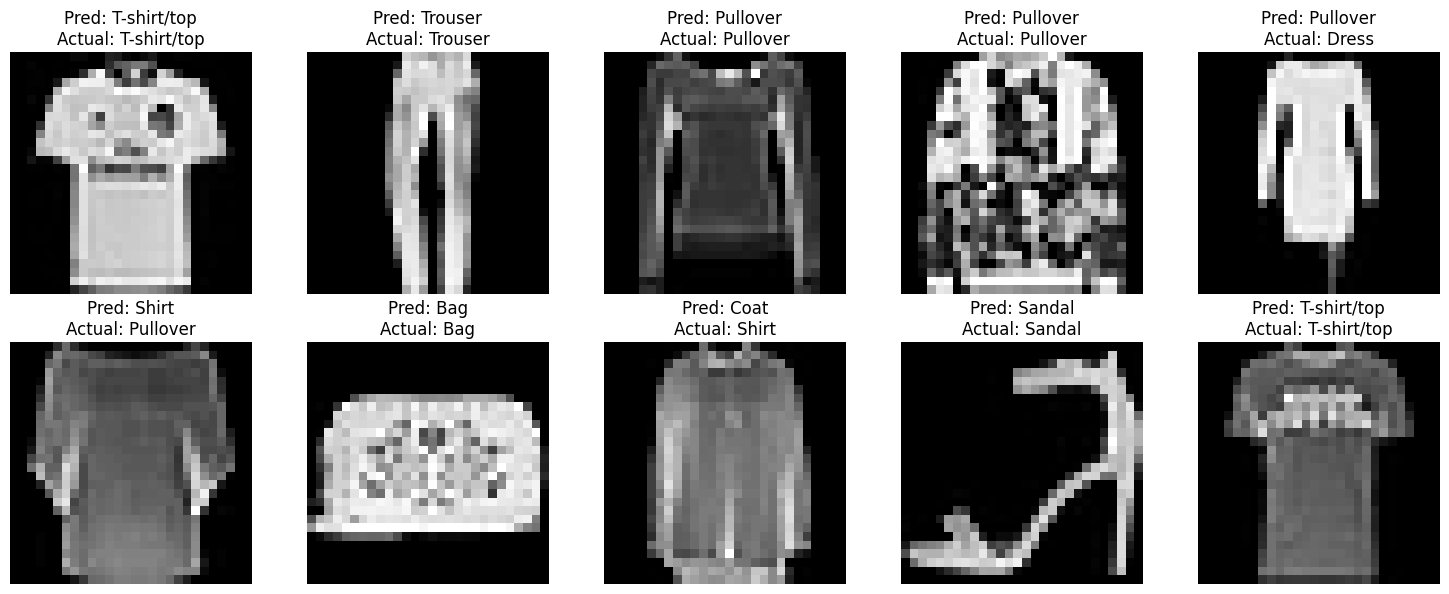

In [49]:
# Show first 10 images
plt.figure(figsize=(15, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    # Convert 784 pixels back to 28 × 28
    image = images[i].reshape(28, 28)

    plt.imshow(image, cmap="gray")

    predicted_class = class_names[predictions[i].item()]
    actual_class = class_names[labels[i].item()]

    plt.title(
        f"Pred: {predicted_class}\n"
        f"Actual: {actual_class}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()